<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/train_for_project_graduate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

In [ ]:
le = LabelEncoder()

In [ ]:
df = pd.read_csv('/content/train.csv')

In [ ]:
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB


In [ ]:
len(df)

165034

In [ ]:
df.isnull().sum()

,0
id,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.shape

(165034, 14)

In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
165029,False
165030,False
165031,False
165032,False


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,165034.0000,1.650340e+05,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,82516.5000,1.569201e+07,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599
std,47641.3565,7.139782e+04,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443
min,0.0000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,41258.2500,1.563314e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000
50%,82516.5000,1.569017e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000
75%,123774.7500,1.575682e+07,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000
max,165033.0000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


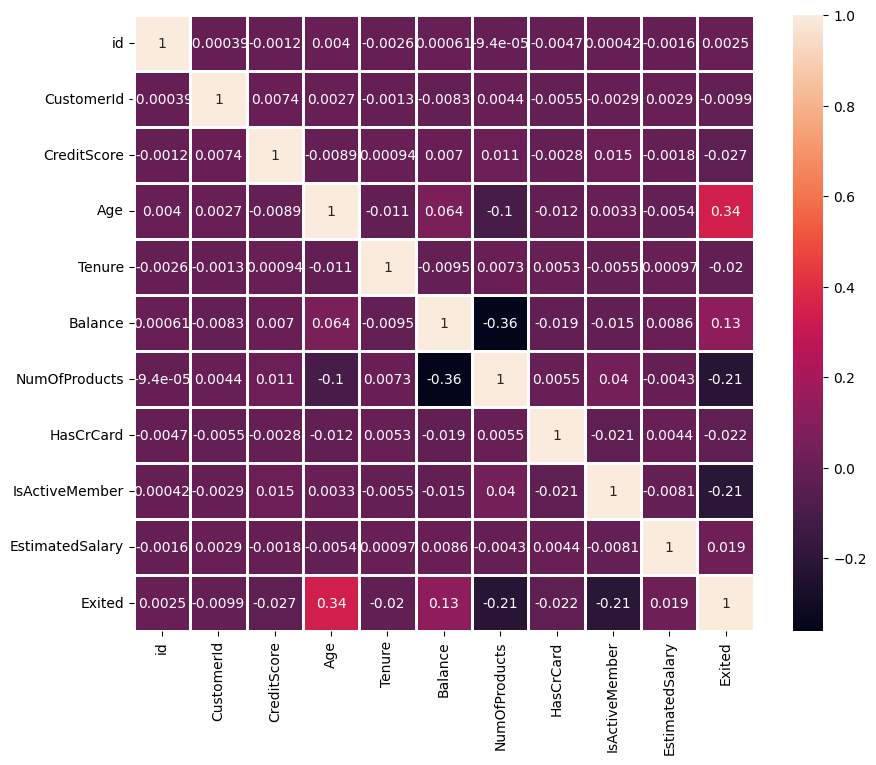

In [ ]:
plt.figure(figsize=(10,8))
numerical_df = df.select_dtypes(include=np.number)
sns.heatmap(numerical_df.corr() , annot=True , linewidths=1 )
plt.show()

Exited
0    130113
1     34921
Name: count, dtype: int64
Exited
0    78.840118
1    21.159882
Name: proportion, dtype: float64


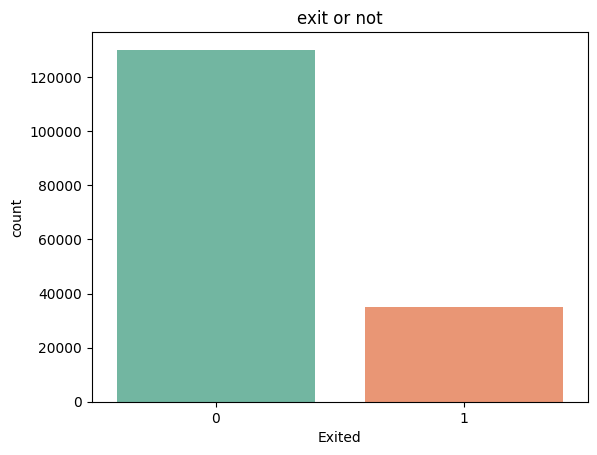

In [ ]:
print(df['Exited'].value_counts())
print(df['Exited'].value_counts(normalize=True) * 100)

sns.countplot(x='Exited', data=df, palette='Set2')
plt.title('exit or not')
plt.show()

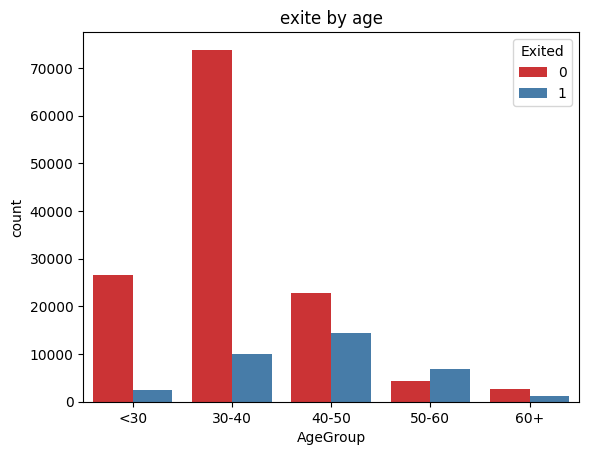

In [ ]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[0,30,40,50,60,100], labels=['<30','30-40','40-50','50-60','60+'])
sns.countplot(x='AgeGroup', hue='Exited', data=df, palette='Set1')
plt.title('exite by age')
plt.show()

#SPLIT DATA



In [ ]:
X = df.drop(['id', 'CustomerId', 'Surname', 'Exited'], axis=1)
y = df['Exited']

# One-hot encode
X = pd.get_dummies(X, columns=['Geography', 'Gender', 'AgeGroup'], drop_first=True)

In [ ]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(X , y , test_size=0.3 , random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(x_train, y_train)

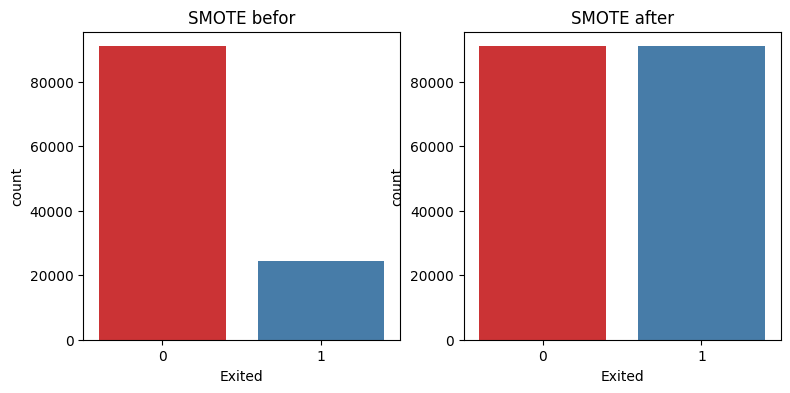

In [ ]:
plt.figure(figsize=(9,4))
plt.subplot(1, 2, 1)
sns.countplot(x=y_train, palette='Set1')
plt.title('SMOTE befor')
plt.subplot(1, 2, 2)
sns.countplot(x=y_train_balanced, palette='Set1')
plt.title('SMOTE after')
plt.show()


In [ ]:
'''models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}'''

"models = {\n    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),\n    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),\n}"

In [ ]:
'''results = {}

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)

    y_pred = model.predict(x_test)

    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred)
    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(model, X_train_balanced, y_train_balanced, cv=5)

    print("Cross Validation Accuracy:", scores.mean())

    results[name] = {'Accuracy': accuracy, 'Recall': recall, 'F1-Score': f1}


    print(f"\n result of model: {name}")
    print(" (Accuracy):", accuracy)
    print(" (Recall):", recall)
    print("F1-Score:", f1)
    print("  (Confusion Matrix):\n", cm)
    print("\n  (Classification Report):\n", classification_report(y_test, y_pred))

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name}')
    plt.xlabel('actule')
    plt.ylabel('predect')
    plt.show()

results_df = pd.DataFrame(results).T
print("\n model runing:")
print(results_df)

results_df.plot(kind='bar', figsize=(10, 6))
plt.title('model runing')
plt.ylabel('value')
plt.xticks(rotation=45)
plt.show()

rf_model = models['Random Forest']
feature_importance = pd.Series(rf_model.feature_importances_, index=pd.DataFrame(X_train_balanced).columns)
feature_importance.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('important of Random Forest')
plt.xlabel('impotrantce')
plt.show()'''

'results = {}\n\nfor name, model in models.items():\n    model.fit(X_train_balanced, y_train_balanced)\n\n    y_pred = model.predict(x_test)\n\n    accuracy = accuracy_score(y_test, y_pred)\n    recall = recall_score(y_test, y_pred, average=\'weighted\')\n    f1 = f1_score(y_test, y_pred, average=\'weighted\')\n    cm = confusion_matrix(y_test, y_pred)\n    from sklearn.model_selection import cross_val_score\n\n    scores = cross_val_score(model, X_train_balanced, y_train_balanced, cv=5)\n\n    print("Cross Validation Accuracy:", scores.mean())\n\n    results[name] = {\'Accuracy\': accuracy, \'Recall\': recall, \'F1-Score\': f1}\n\n\n    print(f"\n result of model: {name}")\n    print(" (Accuracy):", accuracy)\n    print(" (Recall):", recall)\n    print("F1-Score:", f1)\n    print("  (Confusion Matrix):\n", cm)\n    print("\n  (Classification Report):\n", classification_report(y_test, y_pred))\n\n    plt.figure(figsize=(6, 4))\n    sns.heatmap(cm, annot=True, fmt=\'d\', cmap=\'Blues\')

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (Linear)": LinearSVC(random_state=42, max_iter=5000), # أسرع بكثير جداً من SVC
    "Naive Bayes": GaussianNB(),
    # "KNN": KNeighborsClassifier(), # يُفضل حذفه إذا كانت البيانات ضخمة لأنه يبطئ التنبؤ جداً
}

Cross Validation Accuracy: 0.7707119494948185

 result of model: Logistic Regression
 (Accuracy): 0.8123447314738139
 (Recall): 0.8123447314738139
F1-Score: 0.8155782264810714
  (Confusion Matrix):
 [[33964  5169]
 [ 4122  6256]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.89      0.87      0.88     39133
           1       0.55      0.60      0.57     10378

    accuracy                           0.81     49511
   macro avg       0.72      0.74      0.73     49511
weighted avg       0.82      0.81      0.82     49511



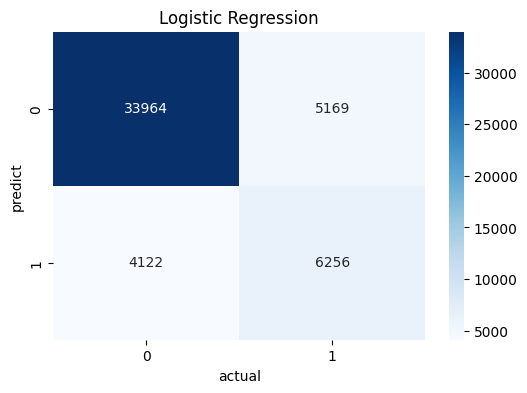

Cross Validation Accuracy: 0.8087766700593763

 result of model: Decision Tree
 (Accuracy): 0.8386621154894872
 (Recall): 0.8386621154894872
F1-Score: 0.842020970607462
  (Confusion Matrix):
 [[34496  4637]
 [ 3351  7027]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.91      0.88      0.90     39133
           1       0.60      0.68      0.64     10378

    accuracy                           0.84     49511
   macro avg       0.76      0.78      0.77     49511
weighted avg       0.85      0.84      0.84     49511



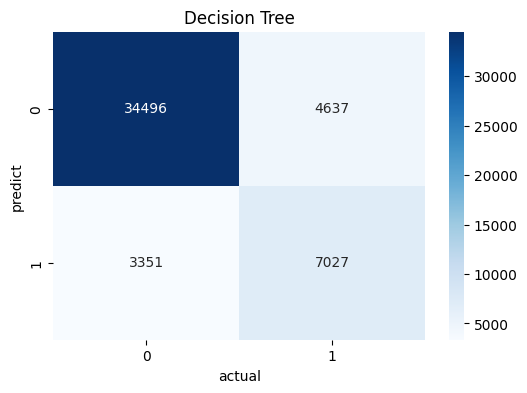

Cross Validation Accuracy: 0.8090033658280562

 result of model: Random Forest
 (Accuracy): 0.83882369574438
 (Recall): 0.83882369574438
F1-Score: 0.8424434501239965
  (Confusion Matrix):
 [[34444  4689]
 [ 3291  7087]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.91      0.88      0.90     39133
           1       0.60      0.68      0.64     10378

    accuracy                           0.84     49511
   macro avg       0.76      0.78      0.77     49511
weighted avg       0.85      0.84      0.84     49511



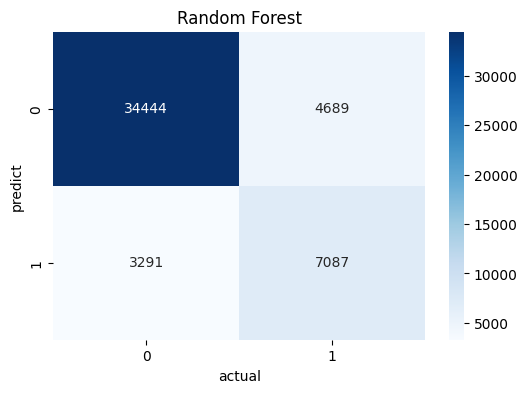

Cross Validation Accuracy: 0.808783511999177

 result of model: Gradient Boosting
 (Accuracy): 0.8372684857910363
 (Recall): 0.8372684857910363
F1-Score: 0.8420390634581746
  (Confusion Matrix):
 [[34161  4972]
 [ 3085  7293]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.92      0.87      0.89     39133
           1       0.59      0.70      0.64     10378

    accuracy                           0.84     49511
   macro avg       0.76      0.79      0.77     49511
weighted avg       0.85      0.84      0.84     49511



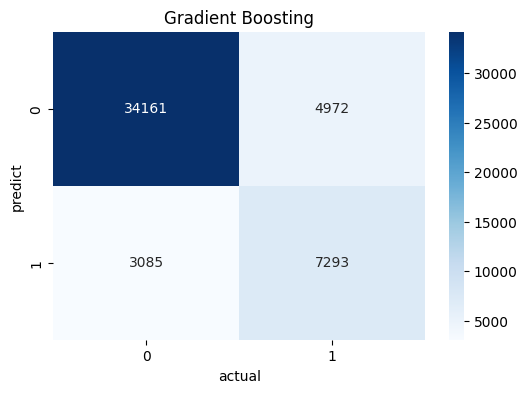

Cross Validation Accuracy: 0.7701005538863626

 result of model: SVM (Linear)
 (Accuracy): 0.8122437438145058
 (Recall): 0.8122437438145058
F1-Score: 0.8156871684394359
  (Confusion Matrix):
 [[33925  5208]
 [ 4088  6290]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.89      0.87      0.88     39133
           1       0.55      0.61      0.58     10378

    accuracy                           0.81     49511
   macro avg       0.72      0.74      0.73     49511
weighted avg       0.82      0.81      0.82     49511



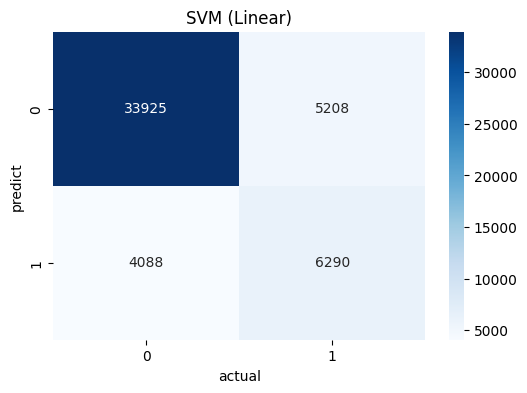

Cross Validation Accuracy: 0.7605860900112302

 result of model: Naive Bayes
 (Accuracy): 0.7942073478620912
 (Recall): 0.7942073478620912
F1-Score: 0.8011270354169789
  (Confusion Matrix):
 [[32932  6201]
 [ 3988  6390]]

  (Classification Report):
               precision    recall  f1-score   support

           0       0.89      0.84      0.87     39133
           1       0.51      0.62      0.56     10378

    accuracy                           0.79     49511
   macro avg       0.70      0.73      0.71     49511
weighted avg       0.81      0.79      0.80     49511



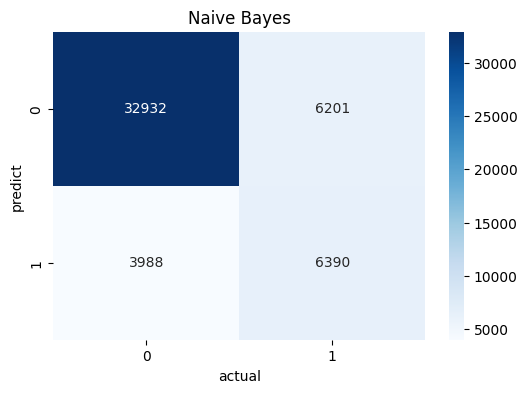


 model running:
                     Accuracy    Recall  F1-Score
Logistic Regression  0.812345  0.812345  0.815578
Decision Tree        0.838662  0.838662  0.842021
Random Forest        0.838824  0.838824  0.842443
Gradient Boosting    0.837268  0.837268  0.842039
SVM (Linear)         0.812244  0.812244  0.815687
Naive Bayes          0.794207  0.794207  0.801127


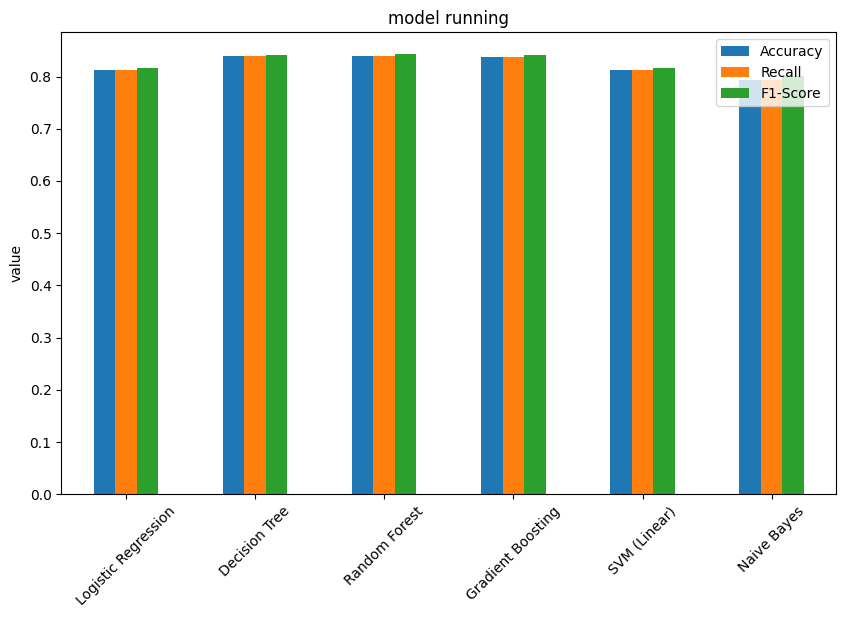

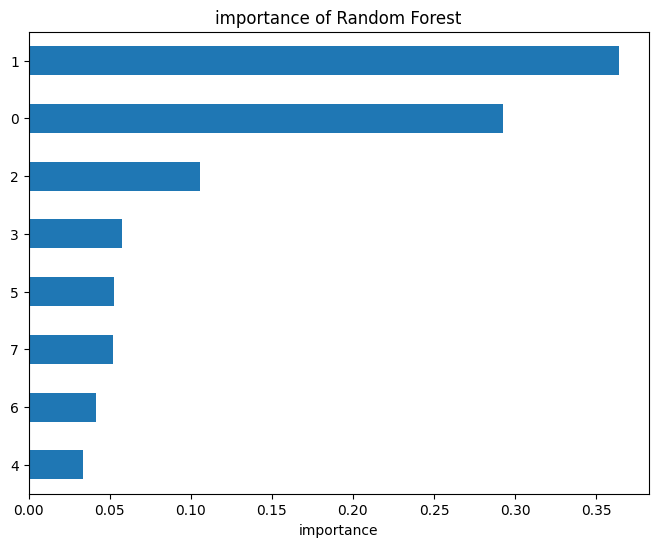

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we have the correct 8-feature balanced dataset in this cell scope
smote_8 = SMOTE(sampling_strategy=0.6, random_state=42)
X_train_balanced_8, y_train_balanced_8 = smote_8.fit_resample(X_train, y_train)

results = {}

# We define clean, isolated model configurations
fresh_models_list = [
    ("Logistic Regression", LogisticRegression(max_iter=5000, random_state=42)),
    ("Decision Tree", DecisionTreeClassifier(random_state=42)),
    ("Random Forest", RandomForestClassifier(random_state=42)),
    ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
    ("SVM (Linear)", LinearSVC(random_state=42, max_iter=5000)),
    ("Naive Bayes", GaussianNB())
]

for name, model in fresh_models_list:
    # Train cleanly on the guaranteed 8-feature dataset
    model.fit(X_train_balanced_8, y_train_balanced_8)

    # Predict on the guaranteed 8-feature test dataset
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred)

    scores = cross_val_score(model, X_train_balanced_8, y_train_balanced_8, cv=5)

    print("Cross Validation Accuracy:", scores.mean())

    results[name] = {'Accuracy': accuracy, 'Recall': recall, 'F1-Score': f1}

    print(f"\n result of model: {name}")
    print(" (Accuracy):", accuracy)
    print(" (Recall):", recall)
    print("F1-Score:", f1)
    print("  (Confusion Matrix):\n", cm)
    print("\n  (Classification Report):\n", classification_report(y_test, y_pred))

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name}')
    plt.xlabel('actual')
    plt.ylabel('predict')
    plt.show()

results_df = pd.DataFrame(results).T
print("\n model running:")
print(results_df)

results_df.plot(kind='bar', figsize=(10, 6))
plt.title('model running')
plt.ylabel('value')
plt.xticks(rotation=45)
plt.show()

# Retrieve the freshly fitted Random Forest model
rf_model = dict(fresh_models_list)['Random Forest']
feature_importance = pd.Series(rf_model.feature_importances_, index=pd.DataFrame(X_train_balanced_8).columns)
feature_importance.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('importance of Random Forest')
plt.xlabel('importance')
plt.show()

In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

# We loop through, train, predict, and evaluate all models in a single continuous block
for name, model in models.items():
    print(f" Training and evaluating: {name}...")
    start_time = time.time()

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Check for probability support to compute ROC-AUC
    if hasattr(model, "predict_proba"):
        y_proba_test = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba_test = model.decision_function(X_test)
    else:
        y_proba_test = y_pred_test

    auc_score = roc_auc_score(y_test, y_proba_test)

    print(f"-> Done in {time.time() - start_time:.2f} seconds\n")

    # Save metrics cleanly
    results.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, y_pred_train),
        'Test Accuracy': accuracy_score(y_test, y_pred_test),
        'Precision (Churn)': precision_score(y_test, y_pred_test, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred_test, zero_division=0),
        'F1 (Churn)': f1_score(y_test, y_pred_test, zero_division=0),
        'ROC-AUC': auc_score,
    })

# Construct the final sorted results DataFrame
results_df = pd.DataFrame(results).sort_values('F1 (Churn)', ascending=False).reset_index(drop=True)

# Display the styled table
display(results_df.style.background_gradient(cmap='Greens', subset=['F1 (Churn)', 'ROC-AUC', 'Recall (Churn)']))

 Training and evaluating: Logistic Regression...
-> Done in 0.22 seconds

 Training and evaluating: Decision Tree...
-> Done in 0.16 seconds

 Training and evaluating: Random Forest...
-> Done in 7.33 seconds

 Training and evaluating: Gradient Boosting...
-> Done in 7.04 seconds

 Training and evaluating: SVM (Linear)...
-> Done in 0.19 seconds

 Training and evaluating: Naive Bayes...
-> Done in 0.11 seconds



,Model,Train Accuracy,Test Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Gradient Boosting,0.859569,0.860152,0.737356,0.516959,0.607794,0.878403
1,Random Forest,0.861378,0.858799,0.735503,0.509636,0.602083,0.874995
2,Decision Tree,0.861378,0.858557,0.737576,0.504818,0.599394,0.873175
3,Naive Bayes,0.823992,0.822969,0.584089,0.539796,0.561070,0.817863
4,Logistic Regression,0.840326,0.840419,0.701219,0.415880,0.522107,0.823956
5,SVM (Linear),0.836751,0.836703,0.703822,0.381480,0.494782,0.823524


#شكل كلمه overfiting

In [ ]:
# Use the correct 8-feature balanced dataset
train_pred = model.predict(X_train_balanced_8)

train_acc = accuracy_score(y_train_balanced_8, train_pred)

# Predict on the 8-feature test set using the active model
y_pred_8 = model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_8)

print("Model:", model.__class__.__name__)
print("Train Accuracy (8 Features):", train_acc)
print("Test Accuracy (8 Features):", test_acc)

Model: GaussianNB
Train Accuracy (8 Features): 0.7652712134535062
Test Accuracy (8 Features): 0.8229686332330189


#حل للover

In [ ]:
RandomForestClassifier(
    max_depth=10,
    min_samples_split=5
)

RandomForestClassifier(max_depth=10, min_samples_split=5)

In [ ]:
cross_val_score(model, X_train_balanced, y_train_balanced)

array([0.73898109, 0.74403715, 0.74019015, 0.74013519, 0.74293801])

In [ ]:
RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

RandomForestClassifier(max_depth=10, min_samples_leaf=5, min_samples_split=10,
                       n_estimators=200, random_state=42)

In [ ]:
SMOTE(sampling_strategy=0.6)

SMOTE(sampling_strategy=0.6)

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X_train_balanced, y_train_balanced, cv=5)

print(scores.mean())

0.7412563200703451


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(score_func=f_classif, k=8)
X = selector.fit_transform(X, y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#smote
smote = SMOTE(sampling_strategy=0.6, random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [150, 200],
    'max_depth': [8, 10],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [3, 5]
}
rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train_balanced, y_train_balanced)

best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 10, 'n_estimators': 200}


In [ ]:
cv_scores = cross_val_score(
    best_model,
    X_train_balanced,
    y_train_balanced,
    cv=5
)

print("Cross Validation Mean:", cv_scores.mean())


In [ ]:
best_model.fit(X_train_balanced, y_train_balanced)

In [ ]:
train_pred = best_model.predict(X_train_balanced)
train_acc = accuracy_score(y_train_balanced, train_pred)

y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

In [ ]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

In [ ]:
import joblib

joblib.dump(best_model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(selector, 'selector.pkl')
joblib.dump(selector.get_feature_names_out(), 'columns.pkl')

print("✅ Model saved correctly")